# exp08: Seleksi Fitur

Membandingkan tanpa seleksi, penyaringan korelasi, serta pemilihan berdasarkan mutual information. Seleksi dipelajari ulang pada training di setiap inner dan outer fold, bukan dari seluruh dataset. Catatan fitur terpilih disimpan per fold.

Dataset: good_acceptable, window 45 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp08"
WINDOW = "window_45s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_45s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,614
1,Medium,650
2,High,854


,id,model,scaler,tune,variant,candidate_count
0,xgboost_selection,xgboost,standard,True,clean,6
1,logistic_selection,logistic,standard,True,clean,6


2118 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,1880,238,3
1,fold_01,Andreas,2035,83,3
2,fold_02,Athaya,1979,139,3
3,fold_03,Fabian,1902,216,3
4,fold_04,Rafi,1863,255,3
5,fold_05,Savitri,1916,202,3
6,fold_06,Shakilla,2054,64,3
7,fold_07,Tio,1943,175,3
8,fold_08,faqih,1900,218,3
9,fold_09,ikhsan,1906,212,3


Complete run verified: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp08\window_45s_step_5s\full_f00a53e47909


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp08\window_45s_step_5s\full_f00a53e47909


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
0,logistic_selection,0.313031,0.311013,0.310174,2118
1,xgboost_selection,0.247875,0.262063,0.248467,2118


,scope,model,label,precision,recall,f1,support
0,pooled,logistic_selection,Low,0.259758,0.314332,0.284451,614
1,pooled,logistic_selection,Medium,0.304918,0.286154,0.295238,650
2,pooled,logistic_selection,High,0.371242,0.332553,0.350834,854
42,pooled,xgboost_selection,Low,0.296791,0.361564,0.325991,614
43,pooled,xgboost_selection,Medium,0.231425,0.292308,0.258328,650
44,pooled,xgboost_selection,High,0.205829,0.132319,0.161083,854


accuracy                     balanced_accuracy            \
                        min    median       max               min    median   
model                                                                         
logistic_selection      0.0  0.290323  0.859375               0.0  0.333333   
xgboost_selection       0.0  0.256303  0.661290               0.0  0.320907   

                             macro_f1                     
                         max      min   median       max  
model                                                     
logistic_selection  0.859375      0.0  0.22478  0.924370  
xgboost_selection   0.410256      0.0  0.19037  0.413066

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

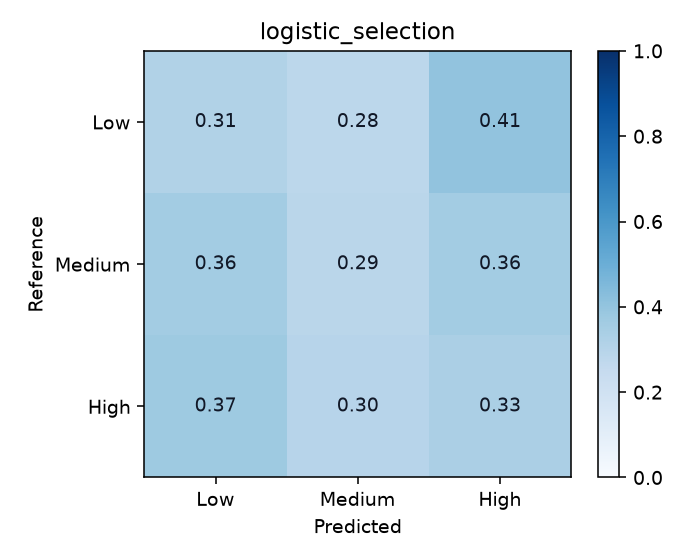

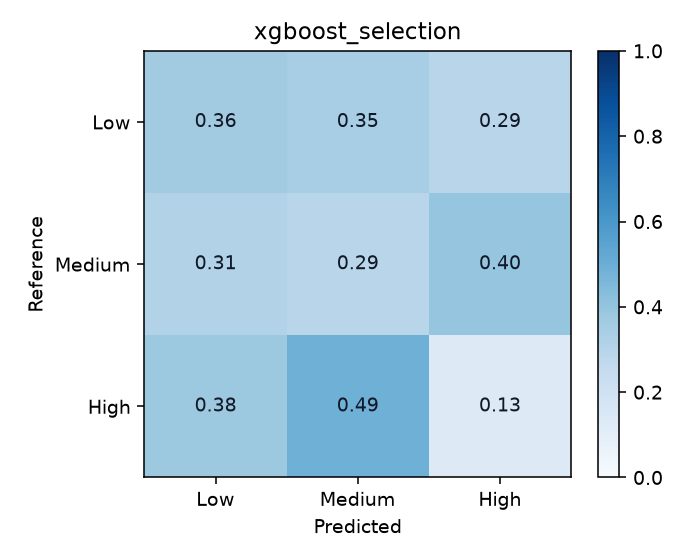

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Stabilitas Seleksi

Frekuensi fitur terpilih antarouter fold membantu melihat apakah seleksi stabil atau berubah mengikuti data training.

In [6]:
stability = pd.read_csv(RESULT_DIR / "feature_stability.csv")
display(pd.crosstab(stability.feature, stability.model))

model,logistic_selection,xgboost_selection
feature,,
blink_rate_per_minute,5,6
ear_left_mean,13,13
ear_left_std,10,9
ear_right_mean,12,8
ear_right_std,4,4
eye_state_fixation_ratio,6,5
eye_state_saccade_ratio,7,4
eye_state_transition_ratio,5,5
eye_state_unclassified_ratio,6,2


### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [7]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp08\window_45s_step_5s\full_f00a53e47909
